# TRABALHO 2 - CÁLCULO NUMÉRICO
## SUAVIZAÇÃO DA TRAJETÓRIA DE UM ROBÔ SEGUIDOR DE LINHA COM CÂMERA VIA MÉTODOS DE JACOBI E GAUSS-SEIDEL

Alunos: Gabriel Lucas Almeida Moreira e Maria Eduarda Saldanha Alves

### CONTEXTO

Um robô seguidor de linha com câmera (por exemplo, Raspberry Pi ou ESP32-CAM) usa a imagem para saber onde está a linha no chão. Há trabalhos que implementam esse tipo de robô usando a câmera como único sensor e a comparam em plataformas como Raspberry Pi e Jetson Nano [2]. A imagem é dividida em N faixas horizontais e, em cada uma, um algoritmo de visão computacional (limiarização, detecção de contorno, centroide) estima a posição lateral da linha, em pixels. A diferença entre essa posição e o centro da imagem é o erro lateral. Em outros trabalhos, esse erro estimado a partir da imagem alimenta um controlador PID, que define a velocidade dos motores [4].

O problema é que as medidas são ruidosas, por causa de sombras, reflexos e falhas na binarização. Se o robô usar a medida bruta, o comando de direção oscila e ele pode perder a pista. Por isso, a posição da linha é suavizada antes de calcular o erro. A suavização por mínimos quadrados penalizados, que combina fidelidade aos dados com penalização de variações bruscas, é uma técnica conhecida [3]. Ela leva a um sistema linear com a mesma estrutura em cada frame, e os métodos iterativos são adequados porque são simples de programar, usam pouca memória e podem reaproveitar a solução do frame anterior como chute inicial [5].


### IMPLEMENTAÇÃO DOS MÉTODOS ITERATIVOS

Os métodos de Jacobi e de Gauss-Seidel foram implementados no arquivo `metodos.py`, a partir do pseudocódigo apresentado nas notas de aula de Cálculo Numérico [6]. Os dois recebem os mesmos argumentos e devolvem os mesmos resultados.

| Argumento | Descrição |
|---|---|
| `A` | matriz dos coeficientes do sistema |
| `b` | vetor dos termos independentes |
| `x0` | chute inicial (deve ser um vetor de números reais) |
| `tol` | tolerância do critério de parada |
| `n` | número máximo de iterações |

| Retorno | Descrição |
|---|---|
| `x` | solução aproximada |
| `k + 1` | número de iterações realizadas |
| `erro` | erro da última iteração, medido pela norma do máximo de x(k) − x(k−1) |

A diferença entre os dois está no cálculo de cada incógnita: o Jacobi usa apenas os valores da iteração anterior (`xant`), enquanto o Gauss-Seidel usa os valores já atualizados na iteração atual para as incógnitas anteriores (`x[j]`, com j < i) e os da iteração anterior para as demais (`x_[j]`, com j > i).

In [25]:
import numpy as np
import matplotlib.pyplot as plt
from metodos import jacobi, gauss_seidel

### ENTRADA DE DADOS

#### Medidas da câmera (N = 8 faixas)

| Faixa $i$ | 1 (topo, longe) | 2 | 3 | 4 | 5 | 6 | 7 | 8 (base, perto) |
|:---:|:---:|:---:|:---:|:---:|:---:|:---:|:---:|:---:|
| Posição medida $y_i$ (px) | 172 | 165 | 178 | 160 | 171 | 150 | 158 | 143 |

#### Parâmetros

| Entrada | Símbolo / variável | Valor do exemplo | Descrição |
|---|---|---|---|
| Nº de faixas | $N$ (`n`) | 8 | também é o nº de equações e de incógnitas |
| Largura da imagem | `largura` | 320 px | |
| Centro da imagem | `centro` | 160 px | referência para o erro lateral |
| Parâmetro de suavização | $\lambda$ (`lam`) | 1,0 | maior $\lambda$ gera uma linha mais suave |
| Chute inicial | $x^{(0)}$ (`x0`) | $x^{(0)} = y$ | a própria medida |
| Tolerância | `tol` | $10^{-8}$ | critério de parada |
| Máx. de iterações | `n_max` | 1000 | |
| Ganho do controle | $k_p$ (`kp`) | 0,01 | usado na aplicação final |


In [26]:
# posicao da linha (em pixels) em cada faixa da imagem
# faixa 0 = topo (longe do robo), ultima faixa = base (perto)
y = np.array([172, 165, 178, 160, 171, 150, 158, 143], dtype=float)

n = len(y)
largura = 320
centro = largura / 2

lam = 1.0
tol = 1e-8
n_max = 1000
x0 = y.copy()    # chute inicial: a propria medida
kp = 0.01

### MONTAGEM DO SISTEMA

As incógnitas são as posições suavizadas x₁, …, xN. Buscamos o x que minimiza a função abaixo, onde o primeiro termo mantém x perto das medidas y e o segundo penaliza saltos entre faixas vizinhas. Esta é a formulação de Eilers (2003) com penalização de diferenças de 1ª ordem.

$$J(x)=\sum_{i=1}^{N}(x_i-y_i)^2+\lambda\sum_{i=1}^{N-1}(x_{i+1}-x_i)^2$$

Derivando J em relação a cada xi e igualando a zero, obtém-se o sistema linear, onde L é a matriz laplaciana discreta (tridiagonal):

$$(I+\lambda L)\,x=y$$

Equação por equação:

$$\begin{aligned}
(1+\lambda)\,x_1-\lambda\,x_2 &= y_1\\
-\lambda\,x_{i-1}+(1+2\lambda)\,x_i-\lambda\,x_{i+1} &= y_i \quad (i=2,\dots,N-1)\\
-\lambda\,x_{N-1}+(1+\lambda)\,x_N &= y_N
\end{aligned}$$

Para N = 8 e λ = 1, a matriz A = I + λL e o vetor b são:

$$A=\begin{bmatrix}
2&-1&0&0&0&0&0&0\\
-1&3&-1&0&0&0&0&0\\
0&-1&3&-1&0&0&0&0\\
0&0&-1&3&-1&0&0&0\\
0&0&0&-1&3&-1&0&0\\
0&0&0&0&-1&3&-1&0\\
0&0&0&0&0&-1&3&-1\\
0&0&0&0&0&0&-1&2
\end{bmatrix},\qquad
b=y=\begin{bmatrix}172\\165\\178\\160\\171\\150\\158\\143\end{bmatrix}$$

#### Fórmulas iterativas

Para as faixas do meio (i = 2, …, N−1):

$$x_i^{(k+1)}=\frac{y_i+\lambda\,x_{i-1}^{(k)}+\lambda\,x_{i+1}^{(k)}}{1+2\lambda}\qquad\text{(Jacobi)}$$

$$x_i^{(k+1)}=\frac{y_i+\lambda\,x_{i-1}^{(k+1)}+\lambda\,x_{i+1}^{(k)}}{1+2\lambda}\qquad\text{(Gauss-Seidel)}$$

Nas faixas 1 e N, o denominador é 1+$\lambda$ e só existe um vizinho.

#### Convergência

Em cada linha, a soma dos módulos dos elementos fora da diagonal é $\lambda$ (primeira e última linhas) ou 2 $\lambda$ (linhas do meio), enquanto o elemento da diagonal vale 1+$\lambda$ ou 1+2 $\lambda$. Logo, A é **estritamente diagonalmente dominante** para qualquer $\lambda$ ≥ 0, o que garante a convergência de Jacobi e de Gauss-Seidel pelo critério das linhas [1].

In [27]:
def montar_sistema(y, lam):
    n = len(y)
    A = np.zeros((n, n))
    for i in range(n):
        A[i, i] = 1 + 2 * lam
        if i > 0:
            A[i, i - 1] = -lam
        if i < n - 1:
            A[i, i + 1] = -lam
    # nas pontas so existe um vizinho
    A[0, 0] = 1 + lam
    A[n - 1, n - 1] = 1 + lam
    return A, y.copy()

def diagonal_dominante(A):
    for i in range(len(A)):
        fora = np.sum(np.abs(A[i])) - abs(A[i, i])
        if abs(A[i, i]) <= fora:
            return False
    return True

A, b = montar_sistema(y, lam)

print("matriz A:")
print(np.round(A, 2))
print("vetor b:", b)
print("estritamente diagonal dominante:", diagonal_dominante(A))

matriz A:
[[ 2. -1.  0.  0.  0.  0.  0.  0.]
 [-1.  3. -1.  0.  0.  0.  0.  0.]
 [ 0. -1.  3. -1.  0.  0.  0.  0.]
 [ 0.  0. -1.  3. -1.  0.  0.  0.]
 [ 0.  0.  0. -1.  3. -1.  0.  0.]
 [ 0.  0.  0.  0. -1.  3. -1.  0.]
 [ 0.  0.  0.  0.  0. -1.  3. -1.]
 [ 0.  0.  0.  0.  0.  0. -1.  2.]]
vetor b: [172. 165. 178. 160. 171. 150. 158. 143.]
estritamente diagonal dominante: True


### SOLUÇÃO COM JACOBI E GAUSS-SEIDEL

In [28]:
import pandas as pd

x_j, it_j, erro_j = jacobi(A, b, x0, tol, n_max)
x_gs, it_gs, erro_gs = gauss_seidel(A, b, x0, tol, n_max)
x_exato = np.linalg.solve(A, b)   # solucao direta, so para comparar

# tabela com a posicao da linha em cada faixa
tabela = pd.DataFrame({
    "faixa": np.arange(1, n + 1),
    "medido": y,
    "jacobi": x_j,
    "gauss-seidel": x_gs,
    "exato": x_exato
})

# tabela resumo dos metodos
resumo = pd.DataFrame({
    "iteracoes": [it_j, it_gs],
    "erro final": [erro_j, erro_gs],
    "dif. para exato": [np.max(np.abs(x_j - x_exato)), np.max(np.abs(x_gs - x_exato))]
})

print(tabela.round(2))
print("\n")
print(resumo)

   faixa  medido  jacobi  gauss-seidel   exato
0      1   172.0  170.29        170.29  170.29
1      2   165.0  168.59        168.59  168.59
2      3   178.0  170.46        170.46  170.46
3      4   160.0  164.81        164.81  164.81
4      5   171.0  163.96        163.96  163.96
5      6   150.0  156.06        156.06  156.06
6      7   158.0  154.22        154.22  154.22
7      8   143.0  148.61        148.61  148.61


   iteracoes    erro final  dif. para exato
0         49  7.076267e-09     2.910781e-09
1         24  7.718086e-09     5.513812e-09


### RESULTADOS

O gráfico compara a posição da linha medida pela câmera (tracejada) com a posição suavizada pelo método de Gauss-Seidel (linha cheia). A curva suavizada varia de forma mais regular entre as faixas vizinhas. A faixa 1 é a mais distante do robô e a faixa 8 é a mais próxima.

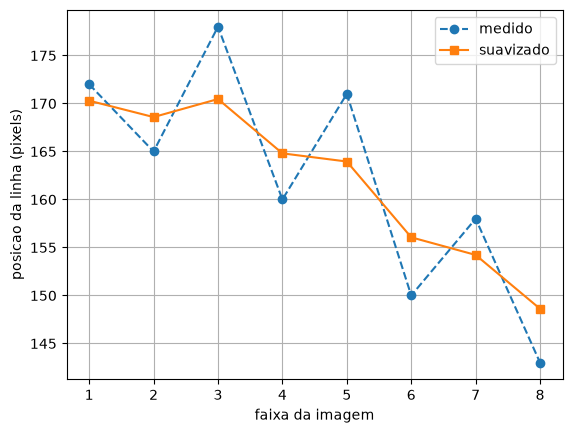

In [29]:
faixas = np.arange(1, n + 1)

plt.plot(faixas, y, "o--", label="medido")
plt.plot(faixas, x_gs, "s-", label="suavizado")
plt.xlabel("faixa da imagem")
plt.ylabel("posicao da linha (pixels)")
plt.legend()
plt.grid()
plt.show()

### CONVERGÊNCIA

Como nos slides da disciplina [6], o erro de cada iteração é a norma do máximo da diferença entre duas iterações seguidas:

$$\text{erro}_k = \|x^{(k)} - x^{(k-1)}\|_\infty$$

Os métodos param quando esse erro fica menor que a tolerância. A tabela mostra o erro nas 15 primeiras iterações. Além disso, verifica-se a convergência pelo critério do raio espectral: o método converge se o raio espectral da matriz de iteração é menor que 1. Para isso, a matriz é decomposta em A = L + D + U, com as matrizes de iteração

$$T_J = -D^{-1}(L+U) \qquad T_G = -(L+D)^{-1}U$$

       jacobi  gauss-seidel
0   10.666667      8.500000
1    7.000000      2.750000
2    4.370370      0.958333
3    2.746914      0.186986
4    1.769547      0.093493
5    1.123800      0.018599
6    0.727481      0.008246
7    0.464811      0.003402
8    0.301021      0.001515
9    0.192930      0.000715
10   0.124864      0.000343
11   0.080170      0.000172
12   0.051843      0.000084
13   0.033324      0.000039
14   0.021534      0.000017


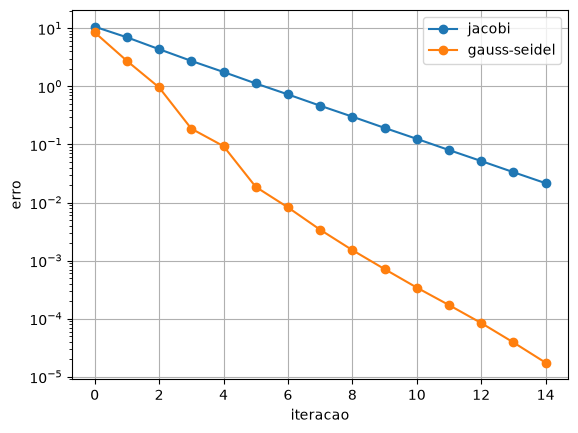

In [ ]:
# roda os metodos com 1, 2, 3, ... iteracoes (tol = 0 nunca para antes)
erros_j = []
erros_gs = []

for m in range(1, 16):
    _, _, e1 = jacobi(A, b, x0, 0, m)
    _, _, e2 = gauss_seidel(A, b, x0, 0, m)
    erros_j.append(e1)
    erros_gs.append(e2)

tabela_erros = pd.DataFrame({"jacobi": erros_j, "gauss-seidel": erros_gs})
print(tabela_erros)

# grafico
# logy - deixa o eixo vertical em escala logarítmica
# mark - coloca uma bolinha em cada ponto
tabela_erros.plot(logy=True, marker="o") 
plt.xlabel("iteracao")
plt.ylabel("erro")
plt.grid()
plt.show()

### EFEITO DO PARÂMETRO $\lambda$

O parâmetro $\lambda$ controla o quanto a linha é suavizada. Quanto maior o $\lambda$, menor a variação entre faixas vizinhas, mas a dominância diagonal da matriz fica mais fraca: a razão entre a soma dos elementos fora da diagonal e o elemento da diagonal passa de $\lambda$/(1+$\lambda$) para valores próximos de 1. Por isso, os métodos precisam de mais iterações.

A coluna "variação total" é a soma dos módulos das diferenças entre faixas vizinhas, ou seja, mede o quanto a linha ainda "treme".

In [33]:
lambdas = [0.1, 0.5, 1, 2, 5, 10, 20]
linhas = []

for l in lambdas:
    A_t, b_t = montar_sistema(y, l)
    xj, itj, _ = jacobi(A_t, b_t, x0, tol, n_max)
    xg, itg, _ = gauss_seidel(A_t, b_t, x0, tol, n_max)
    variacao = np.sum(np.abs(np.diff(xg)))   # diferencas entre faixas vizinhas
    linhas.append([l, itj, itg, variacao])

estudo = pd.DataFrame(linhas, columns=["lambda", "it. jacobi", "it. gauss-seidel", "variacao total (px)"])

print(estudo.round(2))
print(f"variacao total da medida bruta: {np.sum(np.abs(np.diff(y))):.2f} px")

   lambda  it. jacobi  it. gauss-seidel  variacao total (px)
0     0.1          12                 9                67.66
1     0.5          29                16                33.70
2     1.0          49                24                25.44
3     2.0          86                39                19.65
4     5.0         197                83                13.63
5    10.0         382               152                 9.45
6    20.0         749               285                 5.87
variacao total da medida bruta: 93.00 px


### APLICAÇÃO: COMANDO DE DIREÇÃO DO ROBÔ

O erro lateral é a diferença entre a posição da linha na faixa mais próxima do robô (a última) e o centro da imagem. O comando de direção é calculado por um controle proporcional, como nos trabalhos de robôs seguidores de linha com câmera [4]:

$$u = -k_p \, e$$


In [32]:
# erro lateral na faixa mais proxima do robo (a ultima)
erro_bruto = y[-1] - centro
erro_suave = x_gs[-1] - centro

direcao = pd.DataFrame({
    "erro lateral (px)": [erro_bruto, erro_suave],
    "comando": [-kp * erro_bruto, -kp * erro_suave]
})
print(direcao.round(3))

   erro lateral (px)  comando
0            -17.000    0.170
1            -11.388    0.114


### CONCLUSÕES

Neste trabalho, foi desenvolvido um sistema para suavizar a posição da linha detectada pela câmera de um robô seguidor de linha. Para isso, o problema foi representado por um sistema linear $(I + \lambda L)x = y$, com 8 variáveis, e resolvido utilizando os métodos iterativos de Jacobi e Gauss-Seidel.

- **Convergência:** A matriz do sistema apresentou dominância diagonal estrita para qualquer $\lambda \geq 0$, garantindo a convergência dos dois métodos. Para $\lambda = 1$ e tolerância de $10^{-8}$, o método de Jacobi precisou de 49 iterações, enquanto o Gauss-Seidel precisou de apenas 24. Ambos chegaram a resultados muito próximos da solução exata, obtida com `np.linalg.solve`, com diferenças na ordem de $10^{-9}$.

- **Comparação dos métodos:** Foi possível observar que o método de Gauss-Seidel apresentou uma convergência mais rápida, utilizando aproximadamente metade das iterações necessárias pelo método de Jacobi. Isso acontece porque ele utiliza os valores atualizados durante a própria iteração, enquanto Jacobi utiliza os valores da iteração anterior. Esse comportamento também foi observado nos demais valores de $\lambda$ testados.

- **Efeito do $\lambda$:** Conforme o valor de $\lambda$ aumenta, a linha se torna mais suave, reduzindo as variações entre as faixas. Isso pode ser observado pela redução da variação total, que passou de 93 px na medição original para 5,9 px com $\lambda = 20$. Porém, valores maiores também aumentam o número de iterações necessárias para a convergência. Nesse caso, com $\lambda = 20$, Jacobi precisou de 749 iterações e Gauss-Seidel de 285. Portanto, é importante encontrar um equilíbrio entre o nível de suavização desejado e o custo computacional.

- **Aplicação no robô:** A suavização também apresentou resultados positivos em relação ao controle do robô, reduzindo o erro lateral de 17,0 px para 11,4 px. Com isso, o comando de direção tende a ser menos brusco. Entretanto, uma suavização muito intensa pode fazer com que a última faixa acompanhe a tendência das faixas vizinhas, causando um pequeno atraso na identificação de curvas mais fechadas. Por isso, é importante escolher um valor adequado para $\lambda$.

- **Aplicação em sistemas embarcados:** Como o sistema possui apenas 8 variáveis e uma estrutura tridiagonal, seu processamento apresenta baixo custo computacional por iteração. Além disso, em uma aplicação real, seria possível utilizar a solução encontrada no frame anterior como estimativa inicial para o próximo, diminuindo a quantidade de iterações necessárias.

### REFERÊNCIAS

- [1] BURDEN, R. L.; FAIRES, J. D. Análise numérica. 5. ed. São Paulo: Thomson Learning, 2003.

- [2] DEWANTORO, G.; MANSURI, J.; SETIAJI, F. D. Comparative study of computer vision based line followers using Raspberry Pi and Jetson Nano. Jurnal Rekayasa Elektrika, v. 17, n. 4, p. 239-246, dez. 2021. DOI: 10.17529/jre.v17i4.21324. Disponível em: https://doi.org/10.17529/jre.v17i4.21324. Acesso em: 15 nov. 2026.

- [3] EILERS, P. H. C. A perfect smoother. Analytical Chemistry, Washington, v. 75, n. 14, p. 3631-3636, 2003. DOI: 10.1021/ac034173t. Disponível em: https://pubs.acs.org/ancham/article-abstract/75/14/3631/3814879/A-Perfect-Smoother?redirectedFrom=fulltext. Acesso em: 15 nov. 2026.

- [4] FARKH, R. et al. Computer vision-control-based CNN-PID for mobile robot. Computers, Materials & Continua, v. 68, n. 1, 2021. DOI: 10.32604/cmc.2021.016600. Disponível em: https://www.techscience.com/cmc/v68n1/41862. Acesso em: 15 nov. 2026.

- [5] RUGGIERO, M. A. G.; LOPES, V. L. R. Cálculo numérico: aspectos teóricos e computacionais. 2. ed. São Paulo: Makron Books, 1996.

- [6] RIBEIRO, M. R. **Cálculo numérico**: 09 – sistemas lineares – métodos iterativos. Bambuí: Instituto Federal de Minas Gerais, Departamento de Engenharia e Computação, 2024. Notas de aula (slides).